# This notebook shows an example of a Mann-Withney-U Test in a PA research context


In [1]:
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_excel("mann_whitney_physical_activity_teaching_dataset.xlsx")
df.head()

,participant_id,group,age_years,baseline_walking_min_week,followup_walking_min_week,change_min_week
0,PA001,Control,65,170,196,26
1,PA002,Control,37,85,77,-8
2,PA003,Control,47,215,204,-11
3,PA004,Control,48,81,113,32
4,PA005,Control,52,97,122,25


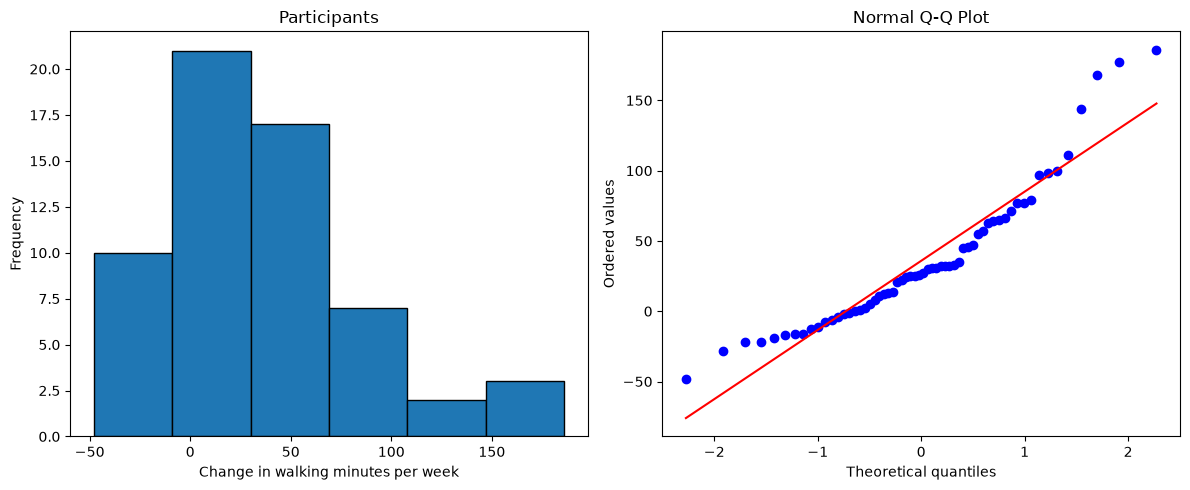

In [11]:
combined_data = df["change_min_week"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(combined_data, bins=6, edgecolor="black")
axes[0].set_title("Participants")
axes[0].set_xlabel("Change in walking minutes per week")
axes[0].set_ylabel("Frequency")

scipy.stats.probplot(combined_data, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q Plot")
axes[1].set_xlabel("Theoretical quantiles")
axes[1].set_ylabel("Ordered values")

fig.tight_layout()
plt.show()

In [10]:
control_change = df.loc[df["group"] == "Control", "change_min_week"].dropna()
intervention_change = df.loc[df["group"] == "Intervention", "change_min_week"].dropna()

mann_whitney_result = scipy.stats.mannwhitneyu(
    control_change,
    intervention_change,
    alternative="less"
)

print("One-sided hypothesis: Control weekly change < Intervention weekly change")
print(f"Control sample size: {len(control_change)}")
print(f"Intervention sample size: {len(intervention_change)}")
print(f"Control median weekly change: {control_change.median():.1f}")
print(f"Intervention median weekly change: {intervention_change.median():.1f}")
print(f"Mann-Whitney U statistic: {mann_whitney_result.statistic:.1f}")
print(f"One-sided p-value: {mann_whitney_result.pvalue:.6f}")

One-sided hypothesis: Control weekly change < Intervention weekly change
Control sample size: 30
Intervention sample size: 30
Control median weekly change: 13.5
Intervention median weekly change: 60.0
Mann-Whitney U statistic: 180.0
One-sided p-value: 0.000034


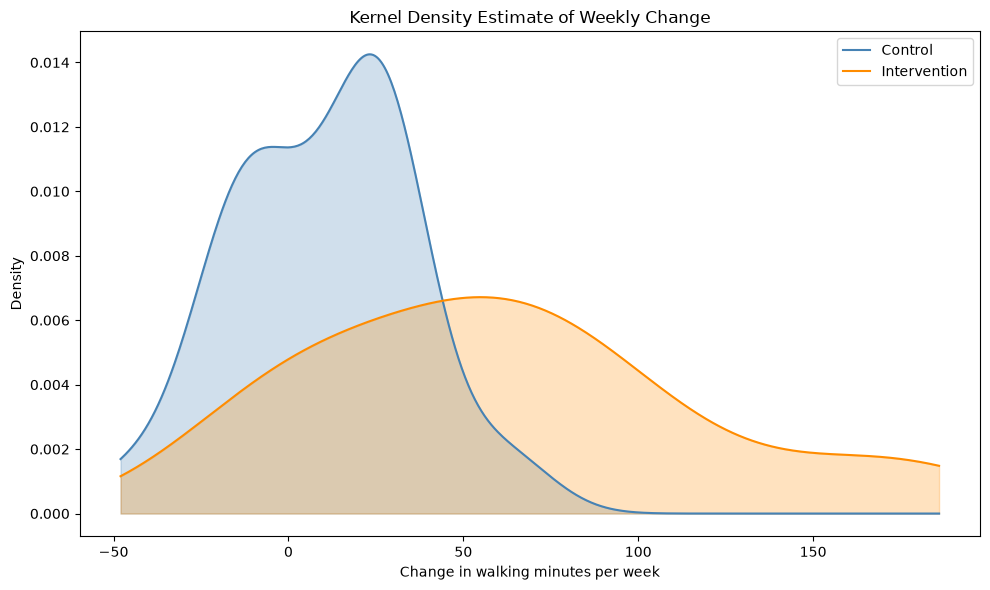

In [12]:
control_density = scipy.stats.gaussian_kde(control_change)
intervention_density = scipy.stats.gaussian_kde(intervention_change)

x_values = np.linspace(
    min(control_change.min(), intervention_change.min()),
    max(control_change.max(), intervention_change.max()),
    500
)

control_y = control_density(x_values)
intervention_y = intervention_density(x_values)

plt.figure(figsize=(10, 6))
plt.plot(x_values, control_y, color="steelblue", label="Control")
plt.fill_between(x_values, control_y, color="steelblue", alpha=0.25)
plt.plot(x_values, intervention_y, color="darkorange", label="Intervention")
plt.fill_between(x_values, intervention_y, color="darkorange", alpha=0.25)
plt.title("Kernel Density Estimate of Weekly Change")
plt.xlabel("Change in walking minutes per week")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()